# PathSnap report figures: data analysis and preprocessing

Every figure for the EDA / preprocessing sections of the technical report, generated from the saved outputs of
`PathSnap_Preprocessing.ipynb` (run that first). Nothing is re-fitted here. Each figure title and caption states the **partition** it uses.
The drop rule removed 0 rows, so the cleaned point set equals the raw one; the plots therefore focus on the model-ready data.
The evaluator partition is never opened. Figures: `cleaned_data/validation/report_figures/`; captions: `CAPTIONS.md` in that folder.

In [1]:
"""Setup: paths, saved tables, figure helper that records a caption with the partition for every figure."""
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, folium
from pyproj import Transformer
HERE = Path.cwd(); sys.path.insert(0, str(HERE))
import pathsnap_prep as P
ROOT = P.find_repo_root(HERE); DATA = ROOT / "Dataset"; CACHE = HERE / "cache"
OUTD = ROOT / "data_preprocessing" / "cleaned_data"; VAL = OUTD / "validation"; MODEL = OUTD / "model_data"
FIG = VAL / "report_figures"; FIG.mkdir(parents=True, exist_ok=True)
CFG = json.loads((HERE / "preprocessing_config.json").read_text())
SEED = CFG["seed"]; plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
COL = {"train": "#1f77b4", "student_test": "#ff7f0e"}; QCOL = {"clean": "#2ca02c", "ambiguous": "#ffbf00", "far": "#d62728"}
CAPTIONS = []
def save(fig, name, caption, partition):
    """Save a figure and record its caption (with the partition it uses)."""
    fig.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight"); CAPTIONS.append((name, partition, caption)); plt.show()
inv = pd.read_csv(VAL / "trip_inventory.csv", dtype={"trip_id": str})
net = pd.read_csv(VAL / "network_checks_all_trips.csv", dtype={"trip_id": str})
val = pd.read_csv(VAL / "label_validation_per_trip.csv", dtype={"trip_id": str})
flags = {"train": pd.read_parquet(OUTD / "point_flags_train.parquet"), "student_test": pd.read_parquet(OUTD / "point_flags_student.parquet")}
labs = {"train": pd.read_parquet(OUTD / "point_labels_train.parquet"), "student_test": pd.read_parquet(OUTD / "point_labels_student.parquet")}
pts = {"train": pd.read_parquet(MODEL / "points_train.parquet"), "student_test": pd.read_parquet(MODEL / "points_student.parquet")}
dec = pd.read_csv(VAL / "feature_decisions.csv"); miss = pd.read_csv(VAL / "candidate_miss_rate_train.csv"); folds = pd.read_csv(MODEL / "folds.csv", dtype={"trip_id": str})
PN = {"train": "Train (80 trips)", "student_test": "Student-test (10 trips)"}
print({k: len(v) for k, v in flags.items()})

{'train': 208417, 'student_test': 19160}


## 1. Points per trip

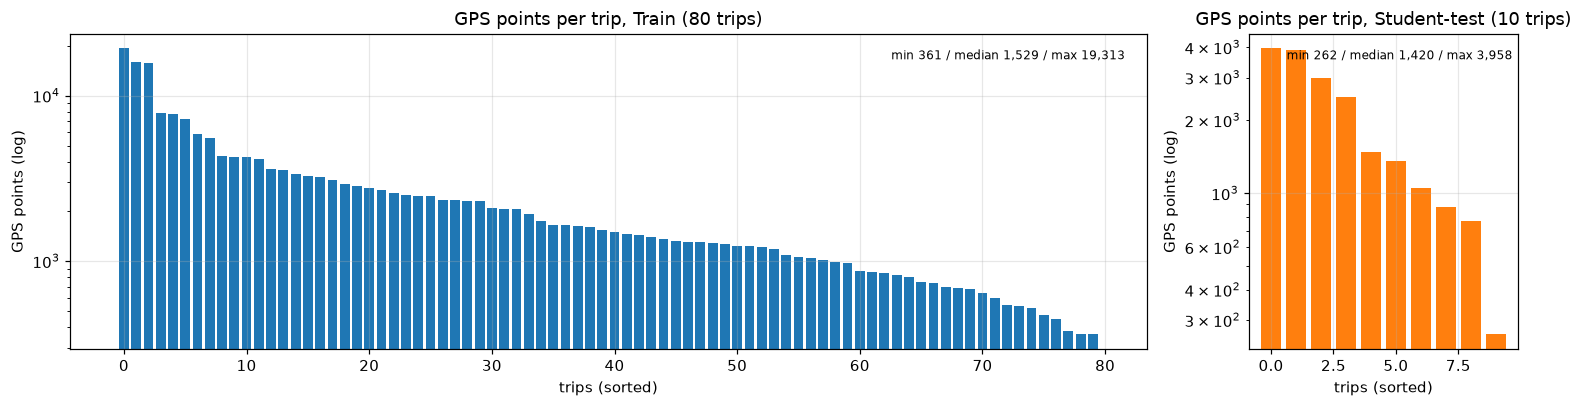

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [4, 1]})
for i, s in enumerate(["train", "student_test"]):
    d = inv[inv.split == s].sort_values("n_gps", ascending=False)
    ax[i].bar(range(len(d)), d.n_gps, color=COL[s]); ax[i].set_yscale("log"); ax[i].set_title(f"GPS points per trip, {PN[s]}")
    ax[i].set_xlabel("trips (sorted)"); ax[i].set_ylabel("GPS points (log)")
    ax[i].text(.98, .92, f"min {d.n_gps.min():,} / median {int(d.n_gps.median()):,} / max {d.n_gps.max():,}", transform=ax[i].transAxes, ha="right", fontsize=8)
plt.tight_layout()
save(fig, "01_points_per_trip", "GPS points per trip, sorted, log scale. Trip sizes vary by more than an order of magnitude.", "Train, Student-test")

## 2. Sampling interval and gaps

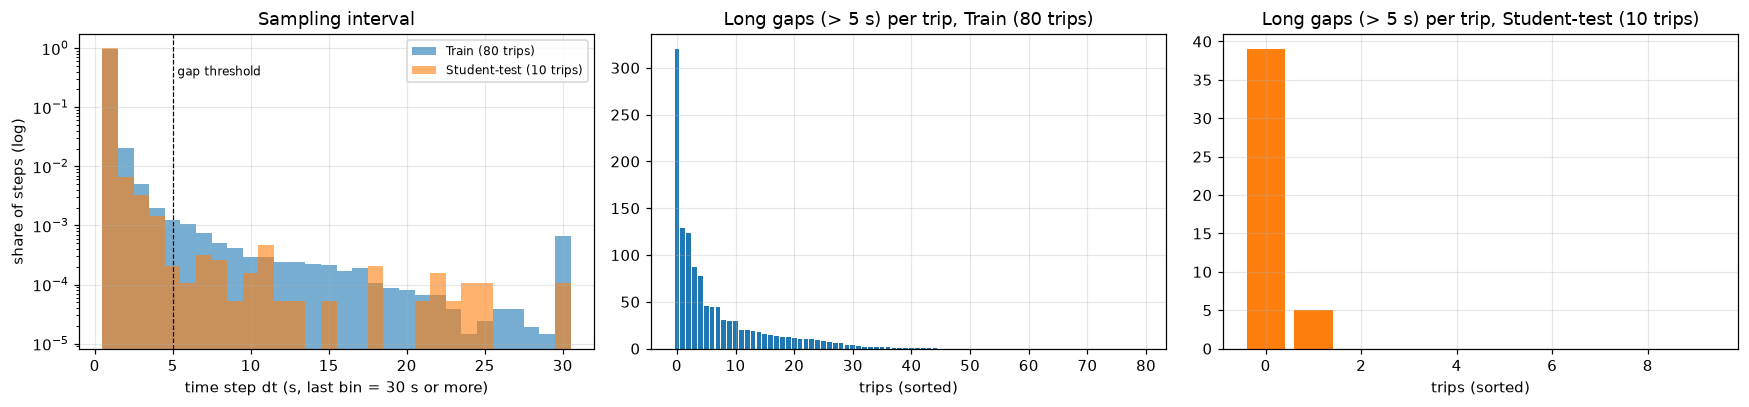

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for s in ["train", "student_test"]:
    dt = flags[s].dt_s.dropna()
    ax[0].hist(np.clip(dt, 0, 30), bins=np.arange(0.5, 31.5, 1.0), alpha=.6, color=COL[s], label=PN[s], weights=np.full(len(dt), 1 / len(dt)))
ax[0].set_yscale("log"); ax[0].set_ylabel("share of steps (log)"); ax[0].set_xlabel("time step dt (s, last bin = 30 s or more)"); ax[0].set_title("Sampling interval"); ax[0].legend(fontsize=8)
ax[0].axvline(CFG["gap_seconds"], c="k", ls="--", lw=.8); ax[0].text(CFG["gap_seconds"] + .3, ax[0].get_ylim()[1] * .2, "gap threshold", fontsize=8)
for i, s in enumerate(["train", "student_test"]):
    g = flags[s].groupby("trip_id").after_gap.sum().sort_values(ascending=False)
    ax[1 + i].bar(range(len(g)), g, color=COL[s]); ax[1 + i].set_title(f"Long gaps (> {CFG['gap_seconds']:g} s) per trip, {PN[s]}"); ax[1 + i].set_xlabel("trips (sorted)")
plt.tight_layout()
save(fig, "02_sampling_and_gaps", "Left: share of time steps between consecutive fixes (log y; dashed line: 5 s gap threshold); almost every step is 1 s. Middle/right: number of long gaps per trip.", "Train, Student-test")

## 3. Speed and step distance with flag counts

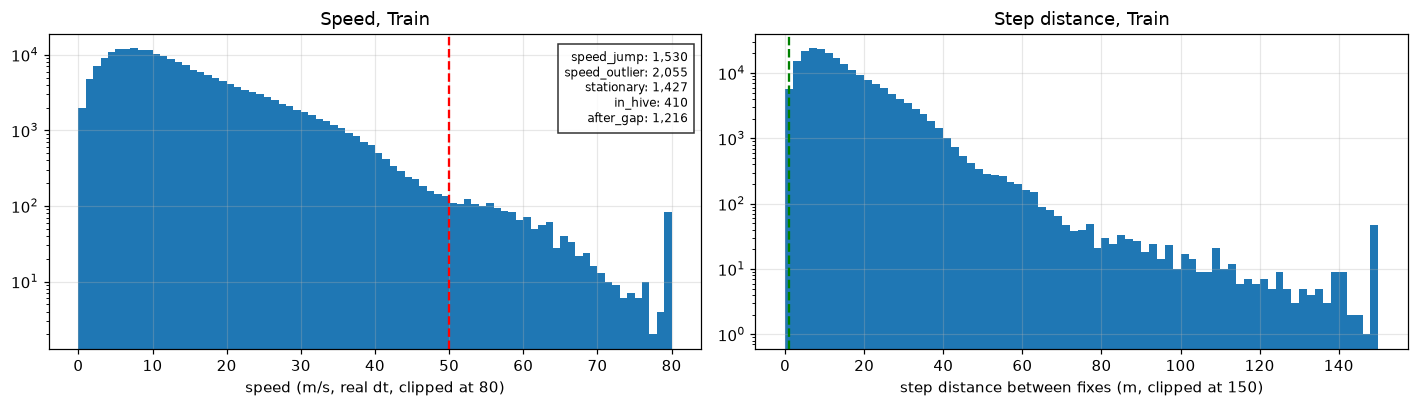

In [4]:
f = flags["train"]; ok = f.dt_s > 0
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(f.speed_mps[ok].clip(upper=80), bins=80, color=COL["train"]); ax[0].set_yscale("log"); ax[0].axvline(CFG["impossible_speed_mps"], c="r", ls="--")
ax[0].set_xlabel("speed (m/s, real dt, clipped at 80)"); ax[0].set_title("Speed, Train")
ax[1].hist(f.step_m[ok].clip(upper=150), bins=75, color=COL["train"]); ax[1].set_yscale("log"); ax[1].axvline(CFG["stationary_step_m"], c="g", ls="--")
ax[1].set_xlabel("step distance between fixes (m, clipped at 150)"); ax[1].set_title("Step distance, Train")
txt = "\n".join(f"{c}: {int(f[c].sum()):,}" for c in ["speed_jump", "speed_outlier", "stationary", "in_hive", "after_gap"])
ax[0].text(.98, .95, txt, transform=ax[0].transAxes, ha="right", va="top", fontsize=8, bbox=dict(fc="white", alpha=.8))
plt.tight_layout()
save(fig, "03_speed_step_flags", "Speed (red line: 50 m/s jump threshold) and step distance (green line: 1 m stationary threshold) with the number of flagged points. Most jumps come from two motorway trips; none coincide with a gap.", "Train")

## 4. Trajectory overview (projected metres)

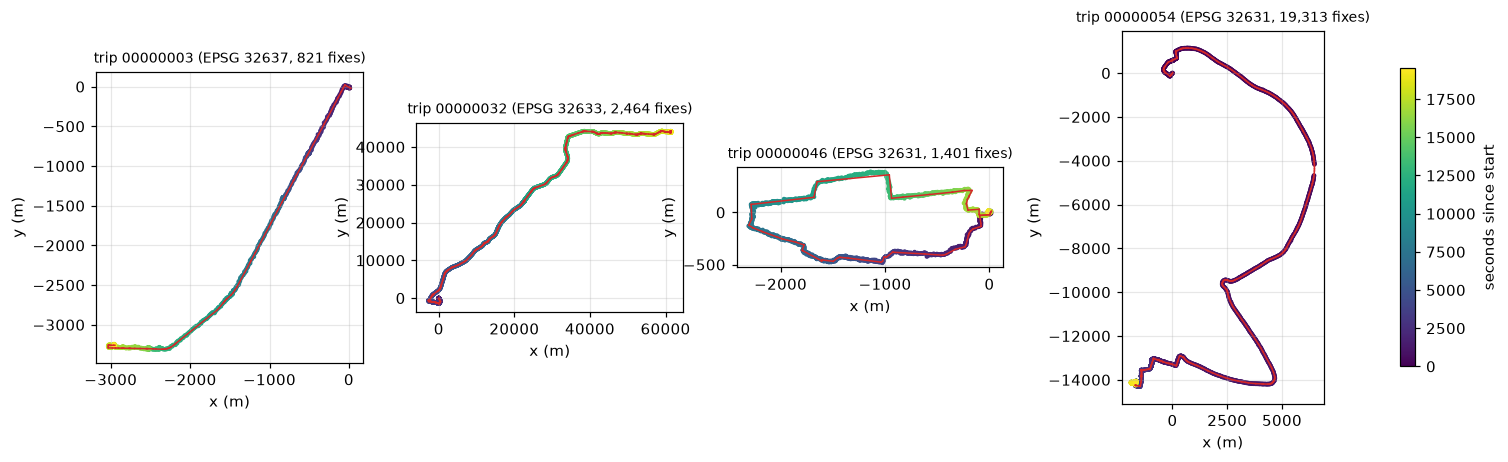

In [5]:
show = ["00000003", "00000032", "00000046", "00000054"]   # short, motorway, loop route, far-heavy
fig, axs = plt.subplots(1, 4, figsize=(18, 4.4))
for ax_, tid in zip(axs, show):
    tr = P.load_trip(DATA, "train", tid, CACHE); route = P.load_route(DATA, "train", tid, tr.n_arcs)
    x0, y0 = tr.gps_xy[0]
    sc = ax_.scatter(tr.gps_xy[:, 0] - x0, tr.gps_xy[:, 1] - y0, c=tr.gps_t - tr.gps_t[0], s=4, cmap="viridis", zorder=1)
    for a in route: ax_.plot([tr.arc_a[a, 0] - x0, tr.arc_b[a, 0] - x0], [tr.arc_a[a, 1] - y0, tr.arc_b[a, 1] - y0], c="#d62728", lw=1.0, zorder=2)
    ax_.set_aspect("equal"); ax_.set_title(f"trip {tid} (EPSG {tr.epsg}, {tr.n_gps:,} fixes)", fontsize=9); ax_.set_xlabel("x (m)"); ax_.set_ylabel("y (m)")
plt.colorbar(sc, ax=axs, shrink=.8, label="seconds since start")
save(fig, "04_trajectory_overview", "GPS fixes coloured by time (dots) and the reference route (thin red line) for four training trips in their own UTM zone: a short trip, a motorway trip, a loop route (00000046, the 1.3% case) and a far-heavy trip (00000054). At this scale the route seems to follow the fixes, but 99% of its far fixes are more than 30 m from every route arc (tens to hundreds of metres, invisible at 15 km scale).", "Train")

## 5. Network size and connectivity

,nodes,arcs,isolated_nodes,weak_components,largest_weak_share,strong_components,largest_strong_share,route_continuity,two_way_arc_share
split,,,,,,,,,
student_test,6596.5,13145.0,0.0,11.0,0.971,53.5,0.961,1.0,0.933
train,9608.0,19526.5,0.0,20.0,0.981,127.0,0.964,1.0,0.951


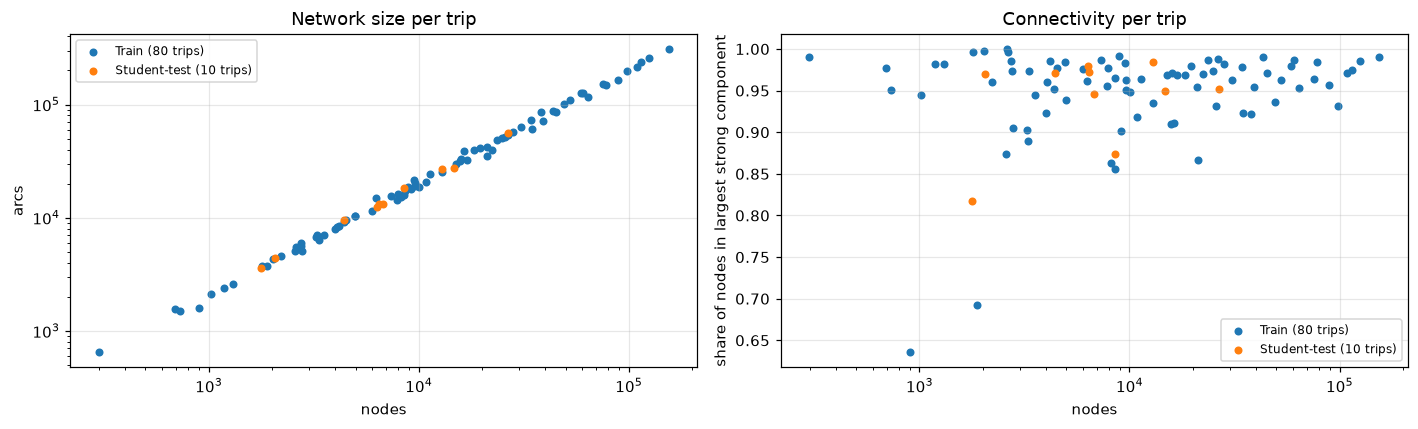

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for s in ["train", "student_test"]:
    d = net[net.split == s]
    ax[0].scatter(d.nodes, d.arcs, s=18, color=COL[s], label=PN[s]); ax[1].scatter(d.nodes, d.largest_strong_share, s=18, color=COL[s], label=PN[s])
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("nodes"); ax[0].set_ylabel("arcs"); ax[0].set_title("Network size per trip"); ax[0].legend(fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("nodes"); ax[1].set_ylabel("share of nodes in largest strong component"); ax[1].set_title("Connectivity per trip"); ax[1].legend(fontsize=8)
plt.tight_layout()
tbl = net.groupby("split")[["nodes", "arcs", "isolated_nodes", "weak_components", "largest_weak_share", "strong_components", "largest_strong_share", "route_continuity", "two_way_arc_share"]].median().round(3)
tbl.to_csv(FIG / "05_network_table_median.csv"); display(tbl)
save(fig, "05_network_size_connectivity", "Road network per trip: arcs vs nodes (about two arcs per node, i.e. two-way roads) and the share of nodes in the largest strongly connected component. No trip has isolated nodes.", "Train, Student-test")

## 6. Label distance and label quality

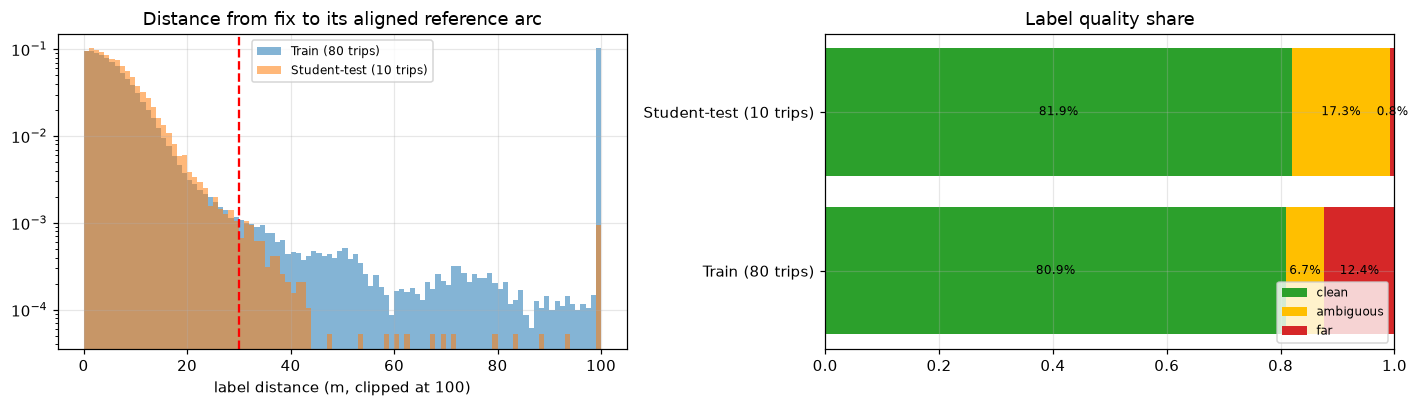

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for s in ["train", "student_test"]:
    ax[0].hist(labs[s].label_distance_m.clip(upper=100), bins=100, alpha=.55, density=True, color=COL[s], label=PN[s])
ax[0].set_yscale("log"); ax[0].axvline(CFG["far_label_m"], c="r", ls="--"); ax[0].set_xlabel("label distance (m, clipped at 100)"); ax[0].set_title("Distance from fix to its aligned reference arc"); ax[0].legend(fontsize=8)
sh = pd.DataFrame({PN[s]: labs[s].label_quality.value_counts(normalize=True) for s in labs}).T[["clean", "ambiguous", "far"]]
left = np.zeros(len(sh))
for q in ["clean", "ambiguous", "far"]:
    ax[1].barh(sh.index, sh[q], left=left, color=QCOL[q], label=q)
    for i, v in enumerate(sh[q]): ax[1].text(left[i] + v / 2, i, f"{v:.1%}", ha="center", va="center", fontsize=8)
    left += sh[q].to_numpy()
ax[1].set_xlim(0, 1); ax[1].legend(fontsize=8, loc="lower right"); ax[1].set_title("Label quality share")
plt.tight_layout()
save(fig, "06_label_distance_quality", "Left: label distance (red line: 30 m far threshold). Right: share of clean / ambiguous / far labels; student-test has more ambiguous labels, train has more far labels.", "Train, Student-test")

## 7. Far share per trip and route recovery

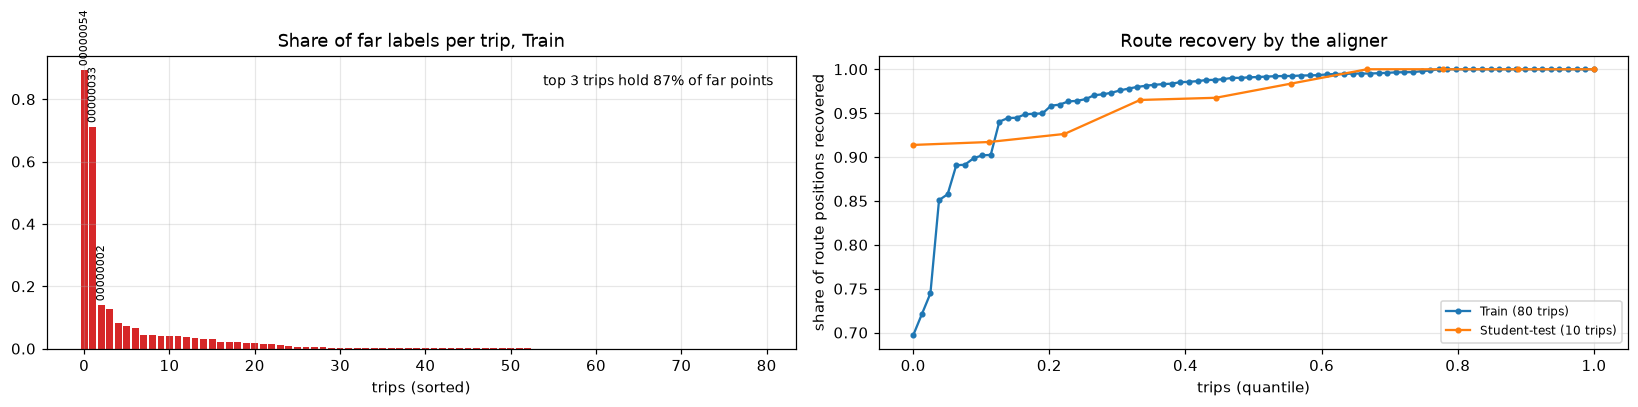

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
d = val[val.split == "train"].sort_values("share_far", ascending=False)
ax[0].bar(range(len(d)), d.share_far, color=QCOL["far"]); ax[0].set_title("Share of far labels per trip, Train"); ax[0].set_xlabel("trips (sorted)")
for i, r in enumerate(d.head(3).itertuples()): ax[0].text(i, r.share_far + .02, r.trip_id, rotation=90, fontsize=7, ha="center")
far_counts = labs["train"].query("label_quality == 'far'").groupby("trip_id").size().sort_values(ascending=False)
ax[0].text(.97, .9, f"top 3 trips hold {far_counts.head(3).sum() / far_counts.sum():.0%} of far points", transform=ax[0].transAxes, ha="right", fontsize=9)
for s in ["train", "student_test"]:
    v = val[val.split == s].sort_values("recovered_share")
    ax[1].plot(np.linspace(0, 1, len(v)), v.recovered_share, "o-", ms=3, color=COL[s], label=PN[s])
ax[1].set_xlabel("trips (quantile)"); ax[1].set_ylabel("share of route positions recovered"); ax[1].set_title("Route recovery by the aligner"); ax[1].legend(fontsize=8)
plt.tight_layout()
save(fig, "07_far_share_route_recovery", "Left: share of far labels per training trip; three trips hold most far points; there, almost every far fix is more than 30 m from every arc of the reference route, so the route does not describe where the vehicle drove. Right: share of reference-route positions recovered, in order, by the route-constrained Viterbi aligner.", "Train (left), Train and Student-test (right)")

## 8. Candidates per point and candidate source

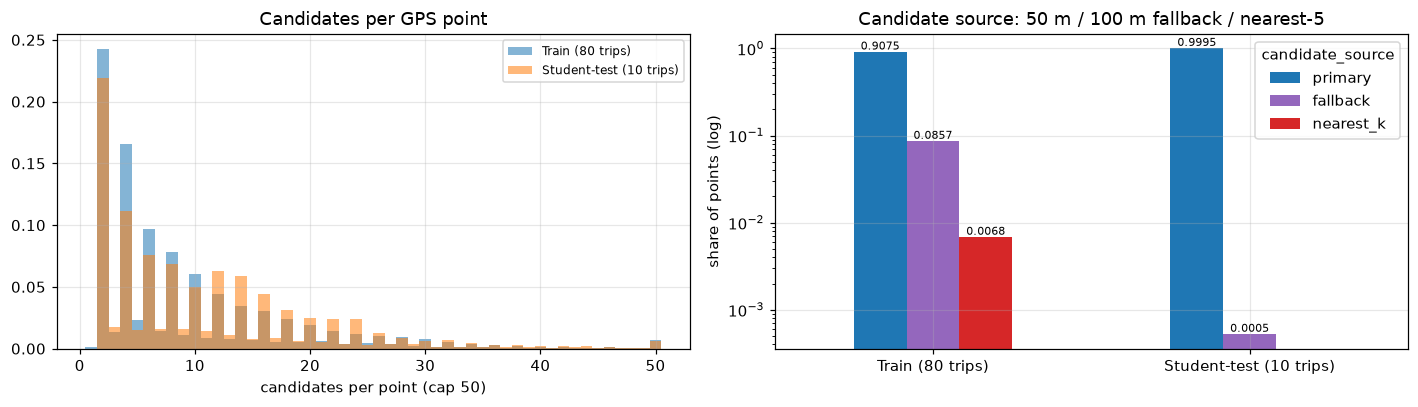

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for s in ["train", "student_test"]:
    ax[0].hist(pts[s].n_candidates, bins=np.arange(0.5, 51.5), alpha=.55, density=True, color=COL[s], label=PN[s])
ax[0].set_xlabel("candidates per point (cap 50)"); ax[0].set_title("Candidates per GPS point"); ax[0].legend(fontsize=8)
src = pd.DataFrame({PN[s]: pts[s].candidate_source.value_counts(normalize=True) for s in pts}).T.reindex(columns=["primary", "fallback", "nearest_k"]).fillna(0)
src.plot.bar(ax=ax[1], color=["#1f77b4", "#9467bd", "#d62728"], rot=0); ax[1].set_yscale("log"); ax[1].set_ylabel("share of points (log)"); ax[1].set_title("Candidate source: 50 m / 100 m fallback / nearest-5")
for c in ax[1].containers: ax[1].bar_label(c, fmt="%.4f", fontsize=7)
plt.tight_layout()
save(fig, "08_candidates_and_source", "Left: number of candidate arcs per point; even counts dominate because a two-way road contributes two opposite arcs. Right: share of points whose candidates come from the 50 m radius, the 100 m fallback, or the 5 nearest arcs.", "Train, Student-test")

## 9. Miss rate vs candidates

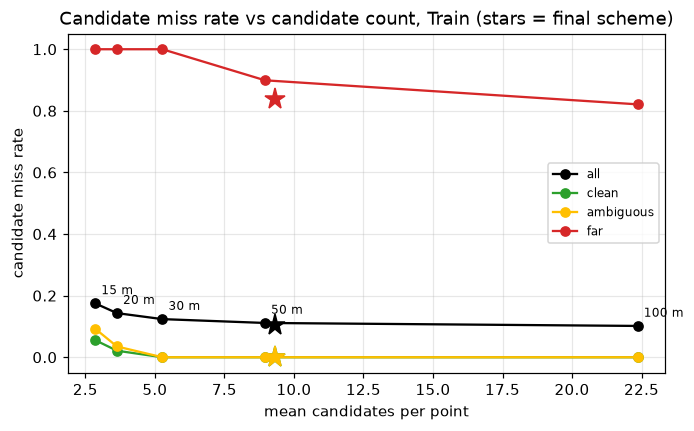

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
r = miss.iloc[:-1]; f_ = miss.iloc[-1]
for col, c in [("miss_all", "k"), ("miss_clean", QCOL["clean"]), ("miss_ambiguous", QCOL["ambiguous"]), ("miss_far", QCOL["far"])]:
    ax.plot(r.mean_cand, r[col], "o-", c=c, label=col.replace("miss_", "")); ax.plot(f_.mean_cand, f_[col], "*", ms=14, c=c)
for x, y, lab_ in zip(r.mean_cand, r.miss_all, r.scheme): ax.annotate(lab_.replace("radius ", ""), (x, y), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlabel("mean candidates per point"); ax.set_ylabel("candidate miss rate"); ax.set_title("Candidate miss rate vs candidate count, Train (stars = final scheme)"); ax.legend(fontsize=8)
save(fig, "09_miss_rate_vs_candidates", "Candidate miss rate for radii 15-100 m and for the final 50 m / 100 m / nearest-5 scheme (stars). Clean and ambiguous labels are within 30 m by definition, so their miss rate is 0 from 30 m upward; far points cause the remaining misses.", "Train")

## 10. Features before and after transform

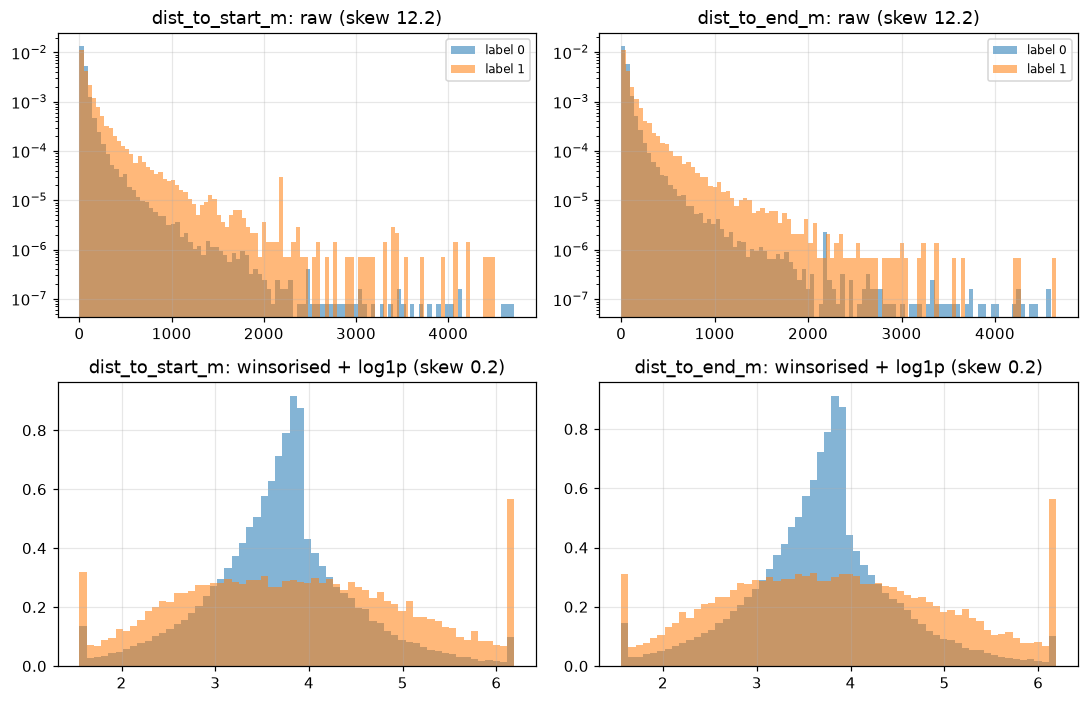

In [11]:
TR = pd.read_parquet(MODEL / "train_candidates.parquet", columns=P.FEATURES + ["label", "fit_include", "fold", "trip_id"])
use = TR[TR.fit_include]; samp = use.sample(n=min(300_000, len(use)), random_state=SEED)
LOGF = CFG["log1p_features"]
fig, axs = plt.subplots(2, len(LOGF), figsize=(5 * len(LOGF), 6.5), squeeze=False)
for j, f in enumerate(LOGF):
    lo, hi = CFG["winsor_bounds"][f]
    for lab_, c in [(0, "C0"), (1, "C1")]:
        x = samp.loc[samp.label == lab_, f]
        axs[0, j].hist(x, bins=100, alpha=.55, density=True, color=c, label=f"label {lab_}")
        axs[1, j].hist(np.log1p(np.clip(x, lo, hi)), bins=60, alpha=.55, density=True, color=c, label=f"label {lab_}")
    axs[0, j].set_yscale("log"); axs[0, j].set_title(f"{f}: raw (skew {samp[f].skew():.1f})"); axs[1, j].set_title(f"{f}: winsorised + log1p (skew {np.log1p(np.clip(samp[f], lo, hi)).skew():.1f})")
    axs[0, j].legend(fontsize=8)
plt.tight_layout()
save(fig, "10_transform_before_after", "Features transformed with log1p, before (top, log y) and after winsorisation at the train 1st/99th percentile plus log1p (bottom), split by label. The spikes at both ends of the bottom plots are the values clipped by winsorisation.", "Train (usable rows)")

## 11. Correlation of all engineered features (kept and dropped)

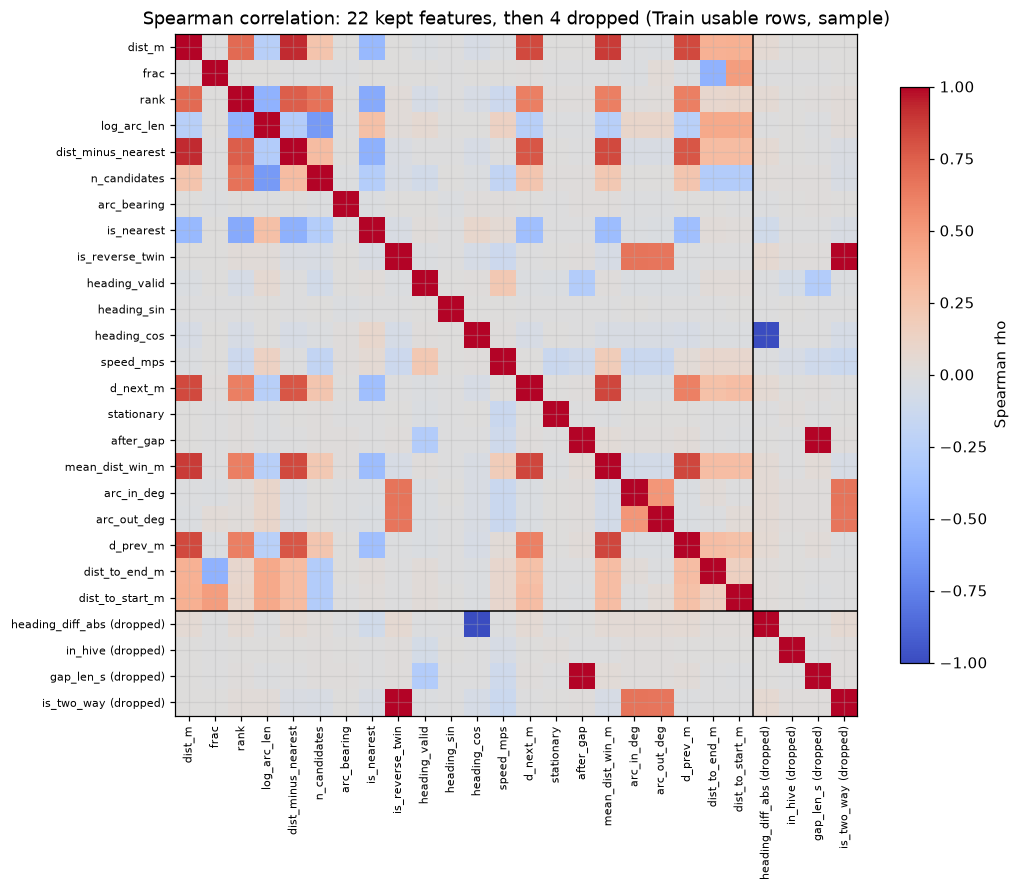

In [12]:
order = dec.sort_values("decision", key=lambda s: s.map({"keep": 0, "transform": 1, "drop": 2})).feature.tolist()
sp = samp[order].corr(method="spearman")
names = [f"{f} (dropped)" if dec.set_index("feature").loc[f, "decision"] == "drop" else f for f in order]
fig, ax = plt.subplots(figsize=(10, 8.5)); im = ax.imshow(sp.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=7); ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=7)
n_keep = int((dec.decision != "drop").sum()); ax.axhline(n_keep - .5, c="k", lw=1); ax.axvline(n_keep - .5, c="k", lw=1)
plt.colorbar(im, shrink=.8, label="Spearman rho"); ax.set_title(f"Spearman correlation: {n_keep} kept features, then {len(order) - n_keep} dropped (Train usable rows, sample)")
save(fig, "11_feature_correlation", "Spearman correlation of all engineered features; the black lines separate the kept features (top-left) from the dropped ones. Each dropped feature duplicates a kept one (|rho| about 1) or is near-constant.", "Train (usable rows, fixed-seed sample)")

## 12. Feature separation (AUC per feature)

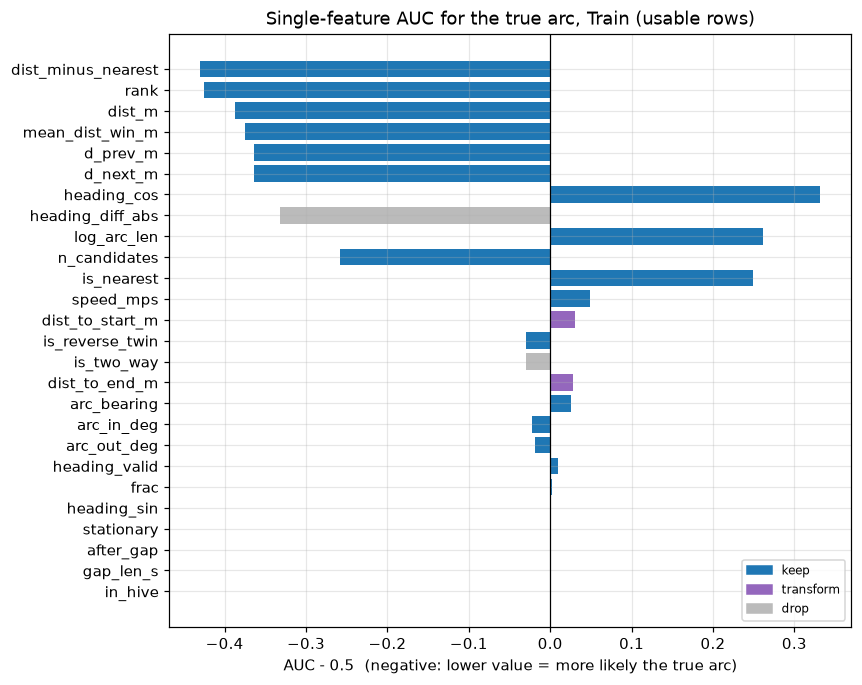

In [13]:
d = dec.assign(edge=(dec.auc - .5).abs()).sort_values("edge")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(d.feature, d.auc - .5, color=d.decision.map({"keep": "#1f77b4", "transform": "#9467bd", "drop": "#bbbbbb"}))
ax.axvline(0, c="k", lw=.8); ax.set_xlabel("AUC - 0.5  (negative: lower value = more likely the true arc)"); ax.set_title("Single-feature AUC for the true arc, Train (usable rows)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#1f77b4", label="keep"), Patch(color="#9467bd", label="transform"), Patch(color="#bbbbbb", label="drop")], fontsize=8, loc="lower right")
save(fig, "12_feature_auc", "How well each feature alone separates the true arc from the other candidates (AUC minus 0.5). Rank and distance features separate best; flags with AUC near 0.5 are kept only where they may help in combination.", "Train (usable rows, fixed-seed sample)")

## 13. Class balance and fit_include

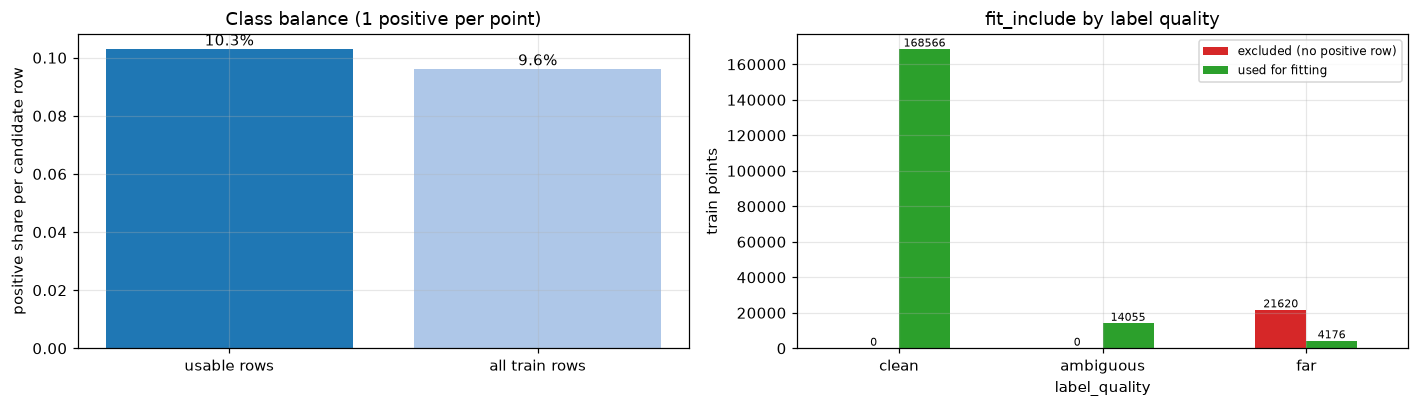

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pos = [use.label.mean(), TR.label.mean()]
ax[0].bar(["usable rows", "all train rows"], pos, color=["#1f77b4", "#aec7e8"]); ax[0].set_ylabel("positive share per candidate row")
for i, v in enumerate(pos): ax[0].text(i, v, f"{v:.1%}", ha="center", va="bottom")
ax[0].set_title("Class balance (1 positive per point)")
fi = pts["train"].groupby(["label_quality", "fit_include"]).size().unstack(fill_value=0).reindex(["clean", "ambiguous", "far"])
fi.plot.bar(ax=ax[1], color=["#d62728", "#2ca02c"], rot=0); ax[1].set_ylabel("train points"); ax[1].set_title("fit_include by label quality")
ax[1].legend(["excluded (no positive row)", "used for fitting"], fontsize=8)
for c in ax[1].containers: ax[1].bar_label(c, fontsize=7)
plt.tight_layout()
save(fig, "13_class_balance_fit_include", "Left: share of positive candidate rows (about one in ten). Right: training points used for fitting vs excluded because their label arc is not among their candidates; every excluded point is a far label.", "Train")

## 14. Fold sizes

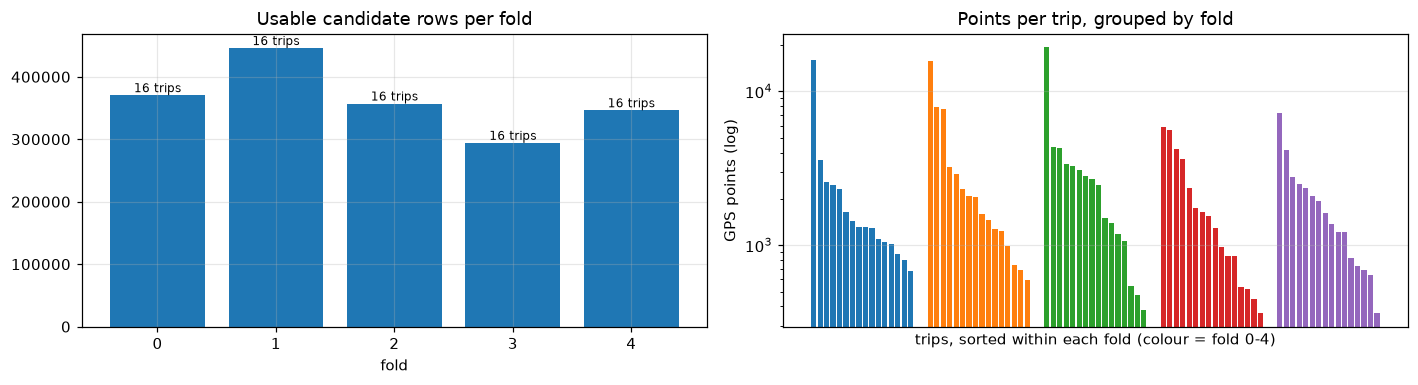

In [15]:
rows_fold = use.groupby("fold").size(); trips_fold = folds.groupby("fold").size(); pts_fold = folds.groupby("fold").n_points.sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(rows_fold.index.astype(str), rows_fold, color="#1f77b4"); ax[0].set_title("Usable candidate rows per fold"); ax[0].set_xlabel("fold")
for i, (k, v) in enumerate(rows_fold.items()): ax[0].text(i, v, f"{trips_fold[k]} trips", ha="center", va="bottom", fontsize=8)
for k in sorted(folds.fold.unique()):
    v = folds[folds.fold == k].n_points.sort_values(ascending=False).to_numpy()
    ax[1].bar(np.arange(len(v)) + k * (len(v) + 2), v, color=f"C{k}")
ax[1].set_yscale("log"); ax[1].set_title("Points per trip, grouped by fold"); ax[1].set_xticks([]); ax[1].set_xlabel("trips, sorted within each fold (colour = fold 0-4)"); ax[1].set_ylabel("GPS points (log)")
plt.tight_layout()
save(fig, "14_fold_sizes", "GroupKFold by trip_id (5 folds, seed 42): usable candidate rows per fold and the trips in each fold. A trip never spans two folds; row counts differ because trip sizes differ.", "Train")

## 15. Folium maps: clean trip, gap-heavy trip, far-heavy trip

In [16]:
g = pts["train"].groupby("trip_id").agg(n=("gps_row", "size"), gaps=("after_gap", "sum"), far=("label_quality", lambda x: (x == "far").mean()))
clean_trip = g[(g.far == 0) & (g.gaps == 0) & (g.n.between(800, 2500))].sort_values("n").index[0]
gap_trip = g[g.n < 6000].assign(r=lambda d: d.gaps / d.n).sort_values("r", ascending=False).index[0]
far_trip = "00000054"
print("clean:", clean_trip, g.loc[clean_trip].to_dict(), "| gap-heavy:", gap_trip, g.loc[gap_trip].to_dict(), "| far-heavy:", far_trip, g.loc[far_trip].to_dict())
def trip_map(tid, title, every=1):
    """Folium map: GPS fixes (blue), reference route (green), points after a gap (purple), far labels (red); legend + layer control."""
    tr = P.load_trip(DATA, "train", tid, CACHE); route = P.load_route(DATA, "train", tid, tr.n_arcs)
    tf = Transformer.from_crs(tr.epsg, 4326, always_xy=True); pp = pts["train"][pts["train"].trip_id == tid]
    m = folium.Map(location=[tr.gps_lonlat[:, 1].mean(), tr.gps_lonlat[:, 0].mean()], zoom_start=13, tiles="OpenStreetMap")
    fg = {k: folium.FeatureGroup(k) for k in ["Reference route (green)", "GPS fixes (blue)", "Points after a gap (purple)", "Far labels (red)"]}
    for a in route:
        lo, la = tf.transform([tr.arc_a[a, 0], tr.arc_b[a, 0]], [tr.arc_a[a, 1], tr.arc_b[a, 1]])
        folium.PolyLine(list(zip(la, lo)), color="green", weight=5, opacity=.8).add_to(fg["Reference route (green)"])
    for r_ in pp.iloc[::every].itertuples():
        ll = (tr.gps_lonlat[r_.gps_row, 1], tr.gps_lonlat[r_.gps_row, 0])
        folium.CircleMarker(ll, radius=2, color="red" if r_.label_quality == "far" else "blue", fill=True).add_to(fg["Far labels (red)" if r_.label_quality == "far" else "GPS fixes (blue)"])
    for r_ in pp[pp.after_gap].itertuples():
        folium.CircleMarker((tr.gps_lonlat[r_.gps_row, 1], tr.gps_lonlat[r_.gps_row, 0]), radius=7, color="purple", fill=True, popup=f"gap {r_.gap_len_s:.0f} s").add_to(fg["Points after a gap (purple)"])
    for f_ in fg.values(): f_.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    lg = (f'<div style="position:fixed;bottom:30px;left:30px;z-index:9999;background:white;padding:8px 10px;border:1px solid #888;font-size:12px"><b>{title}</b><br>'
          '<span style="color:green">&#9473;</span> reference route<br><span style="color:blue">&#9679;</span> GPS fix<br>'
          '<span style="color:purple">&#9679;</span> fix after a long gap<br><span style="color:red">&#9679;</span> far label (no reference arc nearby)</div>')
    m.get_root().html.add_child(folium.Element(lg)); return m
for tid, kind, every in [(clean_trip, "clean", 1), (gap_trip, "gap-heavy", 1), (far_trip, "far-heavy", 4)]:
    m = trip_map(tid, f"Train trip {tid} ({kind})" + (" - every 4th fix shown" if every > 1 else ""), every)
    m.save(FIG / f"15_map_{kind}_{tid}.html")
    CAPTIONS.append((f"15_map_{kind}_{tid}.html", "Train", f"Interactive Folium map of a {kind} training trip: GPS fixes, reference route, points after a long gap and far labels, with layer control and legend."
                     + (" Only every 4th fix is drawn to keep the file small. Zoom in: the far fixes lie tens to hundreds of metres away from the reference route." if every > 1 else "")))
print("maps saved")

clean: 00000003 {'n': 821.0, 'gaps': 0.0, 'far': 0.0} | gap-heavy: 00000004 {'n': 1064.0, 'gaps': 320.0, 'far': 0.045112781954887216} | far-heavy: 00000054 {'n': 19313.0, 'gaps': 6.0, 'far': 0.8939574379951328}


maps saved


In [17]:
"""Write the caption list (figure, partition, caption) for the report."""
lines = ["# Report figures: captions", "", "| Figure | Partition | Caption |", "|---|---|---|"] + [f"| `{n}` | {p} | {c} |" for n, p, c in CAPTIONS]
(FIG / "CAPTIONS.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print(len(CAPTIONS), "figures/maps captioned ->", FIG / "CAPTIONS.md")

17 figures/maps captioned -> C:\Users\Cathy\Desktop\hack 23\PATHSNAP\data_preprocessing\cleaned_data\validation\report_figures\CAPTIONS.md
